In [1]:
from unbiased_mcmc import *

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [2]:
import numpy as np 
def log_target0(x):
    return -0.5 * np.sum(x**2, axis=-1)

def log_target1(x, D):
    return -0.5 * np.sum((x - D)**2, axis=-1)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)

In [3]:
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [4]:

d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)


alpha = 3 #  scale 
D = alpha * np.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)

In [5]:
mk_grid = tune_km_grid(
    lambda_grid,
    mean_init,
    Sigma_init,
    Sigma,
    cholesky_Sigma,
    inv_cholesky_Sigma,
    log_target_path,
    lag=1,
    nrep=1000,
)

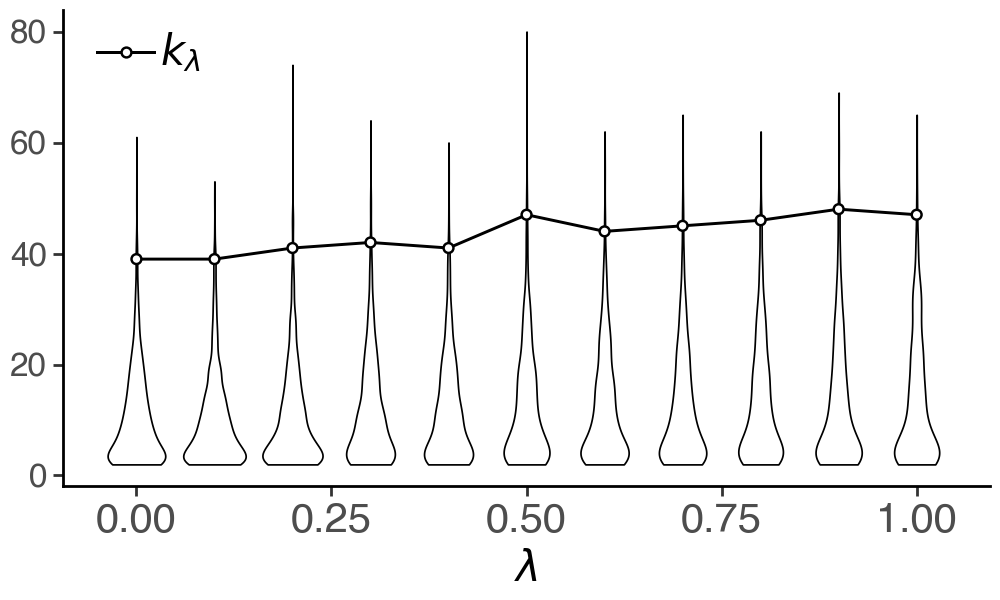

In [6]:
plot_km_grid(mk_grid, lambda_grid)

In [7]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

In [8]:
moment_results = estimate_moments(
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=1000,
    )

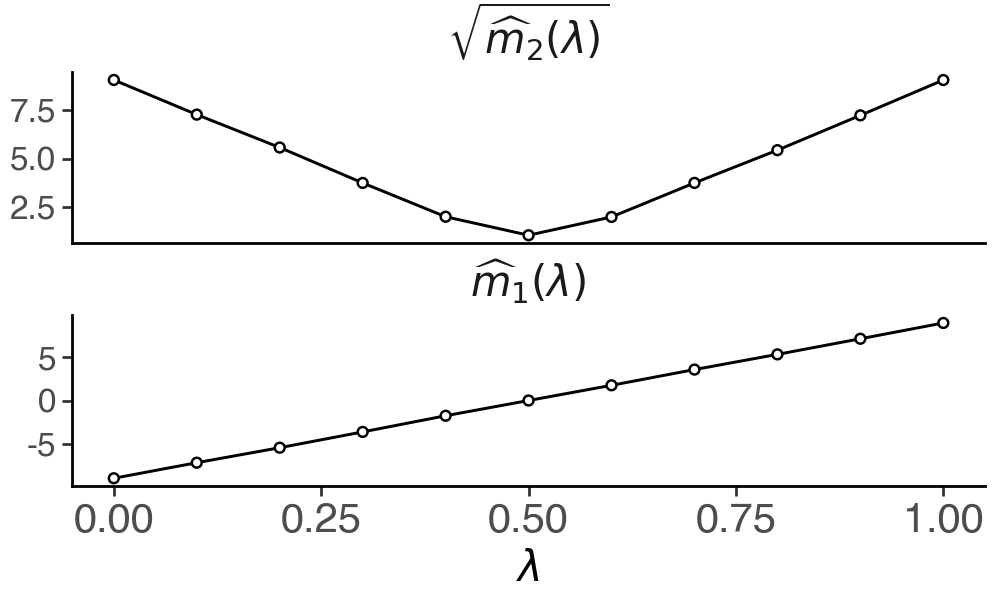

In [9]:
plot_m1_m2(moment_results, lambda_grid)

In [10]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

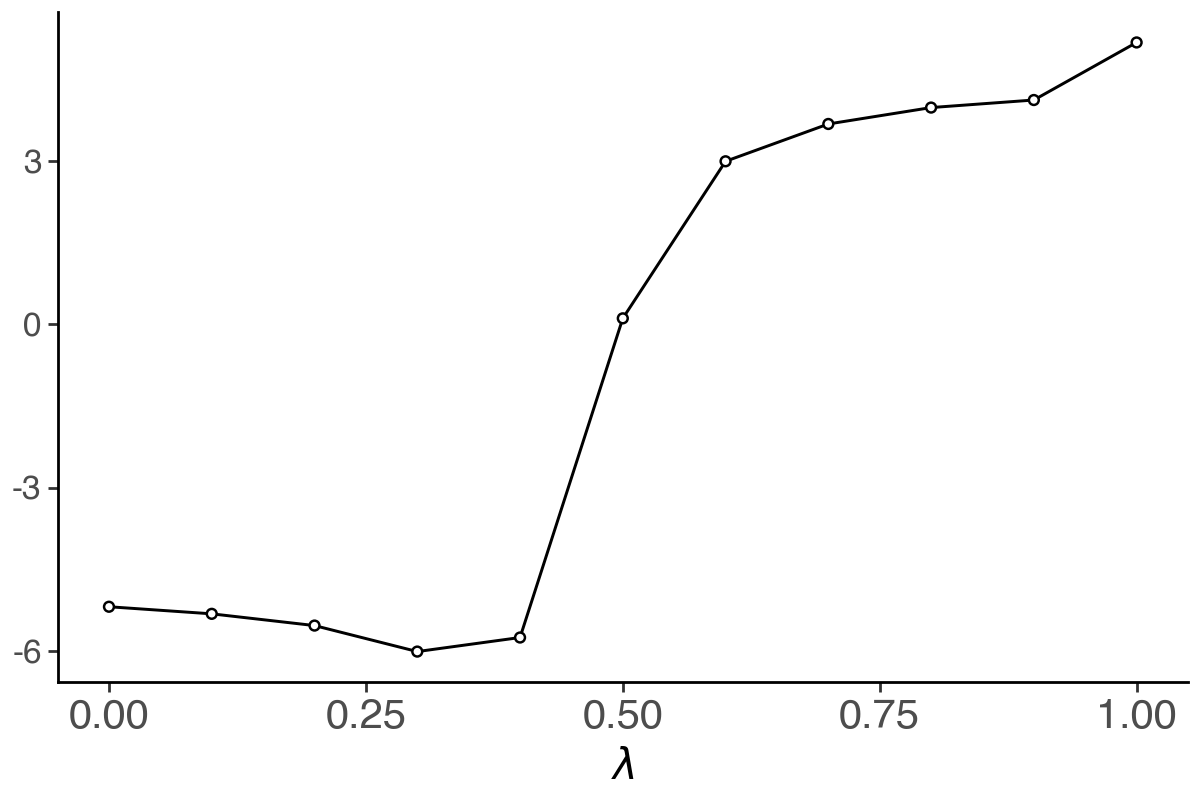

In [11]:
plot_E_lambda_over_q(
	lambda_grid,
	m2,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	nrep=1000,
)

In [11]:
N_pilot = 1000
sigma = estimate_sigma(lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_Sigma, inv_cholesky_Sigma, log_target_path, grad_log_target_path, N_pilot)

IS replications: 100%|██████████| 100/100 [00:00<00:00, 1929.09it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


Workers=14 | M_IS=25727 | coût moyen UPS=25727.7 | coût moyen SUPS=25727.0
MSE: {'UPS': np.float64(0.27997046601075726), 'SUPS': np.float64(0.011101241843337521), 'IS': np.float64(0.6753860378827788)}


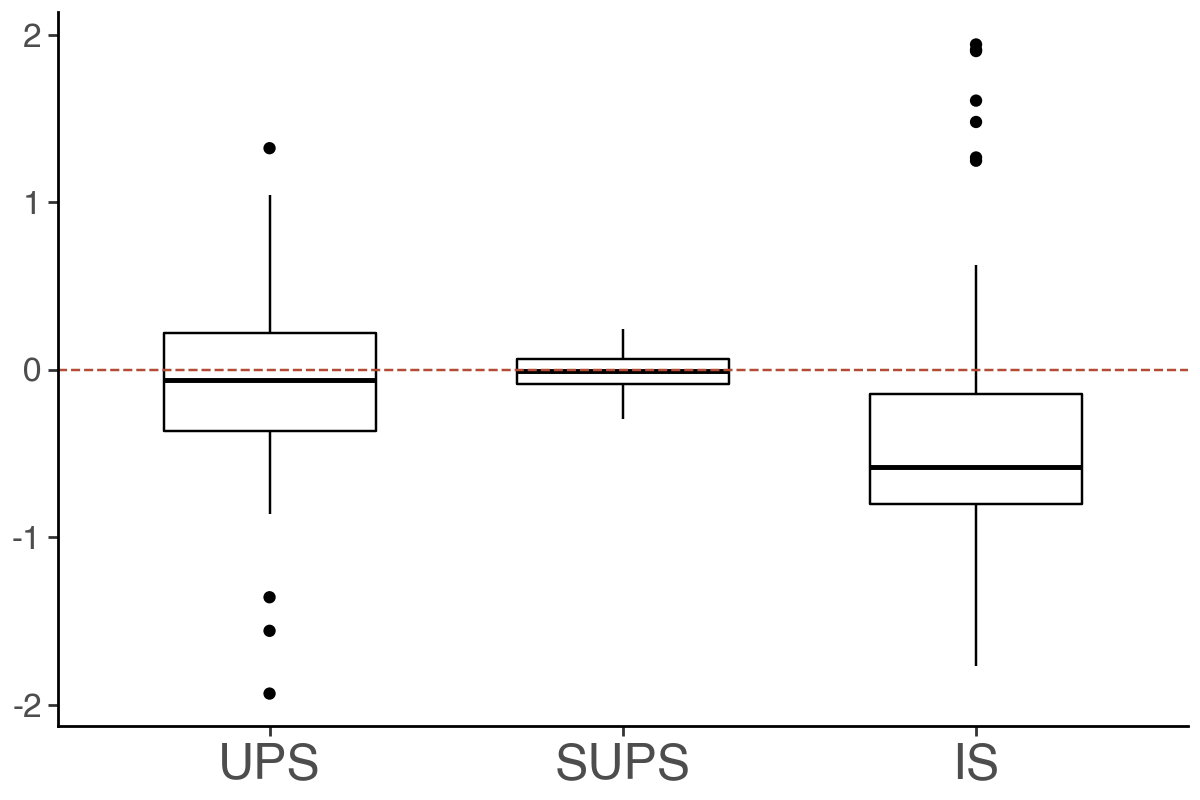

{'UPS_values': array([ 2.12291222e-01, -3.23067980e-02,  1.15941606e-02,  4.15727524e-01,
         6.89592159e-01, -2.73932821e-01, -4.32561042e-01, -1.76112356e-01,
         1.17243297e-01, -2.92594036e-01, -2.76510832e-01,  4.27013828e-02,
         2.65011142e-01,  7.62758747e-02,  1.44900251e-01, -1.78494405e-01,
        -3.82117198e-01, -1.55688981e+00, -1.35611013e-01, -4.76333192e-01,
        -7.19003760e-01, -1.35797966e-01, -1.68233051e-01, -1.26421145e-01,
         7.11065822e-02, -1.35663569e+00, -7.55528323e-01,  1.47767889e-03,
        -8.32697014e-01, -4.32449341e-01, -7.76203284e-01, -1.42161854e-01,
        -6.59730371e-01, -5.18530032e-01, -4.55565001e-01,  4.83591663e-01,
        -8.62229804e-01,  5.85627492e-01,  8.70306073e-02,  3.59037083e-01,
        -1.93124667e+00,  5.24128643e-01,  3.60880886e-01,  2.03551252e-01,
        -3.14295885e-01,  2.36654753e-01,  2.02673510e-01, -5.84843687e-01,
        -2.05091875e-01, -1.64355602e-01, -6.59530184e-01,  9.37872852e-01

In [26]:
compare_estimators(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
    D,
	d,
	M=100,
	nrep=100,
	true_value=0.0,
	n_workers=14,
)

In [ ]:
from IPython.display import display
import importlib

normal_plots = importlib.import_module("unbiased_mcmc.normal_plots")
normal_plots = importlib.reload(normal_plots)
compare_estimators_mse_by_budget = normal_plots.compare_estimators_mse_by_budget

compare_estimators_mse_by_budget(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
	D,
	d,
	M_values=(20, 100, 250, 500, 1000),
	nrep=2,
	true_value=0.0,
	n_workers=14,
	make_plots=False,
)

#tuple(np.geomspace(20, 1000, 5).round().astype(int))
mse_alpha_results = normal_plots.plot_mse_by_alpha(
	lambda_grid,
	Sigma,
	mean_init,
	Sigma_init,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target0,
	log_target1,
)
mse_alpha_results["plot"]


dimension_results = normal_plots.compare_estimators_mse_by_dimension(
	lambda_grid,
	log_target0,
	log_target1,
	dimensions=(2, 4, 8, 16, 32),
	M_by_dimension={2: 50, 4: 100, 8: 200, 16: 500, 32: 1000},
	alpha=3,
	nrep=50,
	n_workers=14,
)

for metric_plot in dimension_results["plots"].values():
	display(metric_plot)
